<a href="https://colab.research.google.com/github/vanshwadhwa24/UCS420/blob/main/UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [11]:
ROLL_NO = 10247120        # <-- your full roll number
NAME = "Vansh Wadhwa"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [12]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [13]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [14]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 10247120   Name: Vansh Wadhwa   Fingerprint: 9A88D18B   Tickets: 12

Ticket_ID                                                                             Ticket_Text
      T01                                   The MATLAB was working yesterday. Can you check this?
      T02                                                  Only 2 of 30 PCs boot after 3.5 hours.
      T03              I tried restarting the laptop on my laptop. The same problem occurs again.
      T04                                  The laptop keeps asking for login. Can you check this?
      T05                  Lms crashes while opening since yesterday. I have tried several times!
      T06 I was locked out of the printer while uploading the file. It works on another computer.
      T07                                                   Nothing works and nobody has replied.
      T08    I can't open the student portal after the latest update. I have tried several times!
      T09                           

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [15]:
results = []
processed_tickets = {}

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]
    processed = process_ticket(text)
    processed_tickets[ticket_id] = processed

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(processed["sentences"]),
        "Tokens": len(processed["tokens"]),
        "Punctuation Tokens": len(processed["punct"]),
        "Stopwords": len(processed["stops"]),
        "Unique Tokens": len(set(processed["tokens"])),
        "Final Tokens": len(processed["final"])
    })

summary_df = pd.DataFrame(results)
total_row = {"Ticket_ID": "TOTAL"}
for col in ["Sentences", "Tokens", "Punctuation Tokens",
            "Stopwords", "Unique Tokens", "Final Tokens"]:
    total_row[col] = summary_df[col].sum()

summary_df = pd.concat([summary_df, pd.DataFrame([total_row])],
                       ignore_index=True)
display(summary_df)

selected_ticket_id = df.iloc[0]["Ticket_ID"]
selected = processed_tickets[selected_ticket_id]
print("Selected Ticket ID:", selected_ticket_id)
print("Original text:", df.iloc[0]["Ticket_Text"])
for label, key in [
    ("Sentences", "sentences"),
    ("Tokens", "tokens"),
    ("Punctuation tokens", "punct"),
    ("Stopwords", "stops"),
    ("Unique tokens", None),
    ("Final tokens", "final")
]:
    print(f"\n{label}:")
    print(sorted(set(selected["tokens"])) if key is None else selected[key])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,11,2,5,11,4
1,T02,1,10,1,3,10,6
2,T03,2,15,2,7,12,6
3,T04,2,12,2,5,12,5
4,T05,2,13,2,3,13,8
5,T06,2,18,2,9,16,7
6,T07,1,7,1,2,7,4
7,T08,2,18,2,6,16,10
8,T09,2,12,2,2,11,8
9,T10,1,9,1,3,9,5


Selected Ticket ID: T01
Original text: The MATLAB was working yesterday. Can you check this?

Sentences:
['The MATLAB was working yesterday.', 'Can you check this?']

Tokens:
['the', 'matlab', 'was', 'working', 'yesterday', '.', 'can', 'you', 'check', 'this', '?']

Punctuation tokens:
['.', '?']

Stopwords:
['the', 'was', 'can', 'you', 'this']

Unique tokens:
['.', '?', 'can', 'check', 'matlab', 'the', 'this', 'was', 'working', 'yesterday', 'you']

Final tokens:
['matlab', 'working', 'yesterday', 'check']


**Your answer:** Some final tokens such as `n't`, `'s`, and `ca` may not be standalone words. They come from the way NLTK's `word_tokenize()` splits contractions (for example, `can't` can become `ca` and `n't`). They remain in the final list if they are neither punctuation-only tokens nor English stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [16]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

raw_texts = df["Ticket_Text"].tolist()
all_texts = raw_texts + TEST_LINES

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    # Match multi-part decimals/versions before ordinary integers.
    "Numbers": r"\b\d+(?:\.\d+)+\b|\b\d+\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

for name, pattern in patterns.items():
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    for i, text in enumerate(all_texts, start=1):
        print(f"Text {i}: {re.findall(pattern, text)}")

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = (
    r"(?<!\w)(?:\+\d{1,3}[-.\s]?)?"
    r"(?:\(?\d{2,4}\)?[-.\s]?)"
    r"\d{3,4}[-.\s]?\d{3,4}(?!\w)"
)

def redact_text(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,!?;:" ) + "<URL>" +
                  m.group(0)[len(m.group(0).rstrip(".,!?;:")):],
                  text, flags=re.IGNORECASE)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\n========== REDACTED TEXTS ==========")
for i, text in enumerate(all_texts, start=1):
    print(f"Text {i}: {redact_text(text)}")


Words longer than 5 letters
Text 1: ['MATLAB', 'working', 'yesterday']
Text 2: []
Text 3: ['restarting', 'laptop', 'laptop', 'problem', 'occurs']
Text 4: ['laptop', 'asking']
Text 5: ['crashes', 'opening', 'yesterday', 'several']
Text 6: ['locked', 'printer', 'uploading', 'another', 'computer']
Text 7: ['Nothing', 'nobody', 'replied']
Text 8: ['student', 'portal', 'latest', 'update', 'several']
Text 9: ['password', 'yesterday', 'Please']
Text 10: []
Text 11: ['unable', 'password', 'resetting', 'password', 'Please', 'resolve']
Text 12: ['Submitted']
Text 13: ['helpdesk', 'thapar', 'thapar', 'thapar']
Text 14: ['Version']
Text 15: []

Numbers
Text 1: []
Text 2: ['2', '30', '3.5']
Text 3: []
Text 4: []
Text 5: []
Text 6: []
Text 7: []
Text 8: []
Text 9: []
Text 10: ['91', '98765', '43210', '0175', '239', '3201']
Text 11: []
Text 12: []
Text 13: []
Text 14: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Text 15: ['5.30']

Capitalized w

**Your answer:** Use the output above to count capitalized matches that occur at the beginning of a sentence. The capitalized-word regex cannot distinguish sentence-initial capitalization from proper nouns by itself, so inspect the raw ticket text and `TEST_LINES` and report the count from your generated dataset.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [17]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Complex patterns come first so they are not split by simpler alternatives.
token_pattern = (
    r"(?:https?://|www\.)[^\s<>]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d[\d().\-\s]{6,}\d|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*|"
    r"\d+|"
    r"[^\w\s]"
)
custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTEST LINE {i}")
    print("Custom tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

ticket_texts = df["Ticket_Text"].tolist()
comparison_rows = []
for ticket_id, text in zip(df["Ticket_ID"], ticket_texts):
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    comparison_rows.append({
        "Ticket_ID": ticket_id,
        "Different?": custom != standard,
        "Custom tokenizer": custom,
        "word_tokenize()": standard
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
print("Tickets tokenized differently:",
      int(comparison_df["Different?"].sum()), "of", len(comparison_df))


TEST LINE 1
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST LINE 2
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST LINE 3
Custom tokenizer: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', 

,Ticket_ID,Different?,Custom tokenizer,word_tokenize()
0,T01,False,"[The, MATLAB, was, working, yesterday, ., Can,...","[The, MATLAB, was, working, yesterday, ., Can,..."
1,T02,False,"[Only, 2, of, 30, PCs, boot, after, 3.5, hours...","[Only, 2, of, 30, PCs, boot, after, 3.5, hours..."
2,T03,False,"[I, tried, restarting, the, laptop, on, my, la...","[I, tried, restarting, the, laptop, on, my, la..."
3,T04,False,"[The, laptop, keeps, asking, for, login, ., Ca...","[The, laptop, keeps, asking, for, login, ., Ca..."
4,T05,False,"[Lms, crashes, while, opening, since, yesterda...","[Lms, crashes, while, opening, since, yesterda..."
5,T06,False,"[I, was, locked, out, of, the, printer, while,...","[I, was, locked, out, of, the, printer, while,..."
6,T07,False,"[Nothing, works, and, nobody, has, replied, .]","[Nothing, works, and, nobody, has, replied, .]"
7,T08,True,"[I, can't, open, the, student, portal, after, ...","[I, ca, n't, open, the, student, portal, after..."
8,T09,True,"[I, can't, open, the, password, since, yesterd...","[I, ca, n't, open, the, password, since, yeste..."
9,T10,True,"[Call, me, on, +91 98765 43210, or, 0175-239-3...","[Call, me, on, +91, 98765, 43210, or, 0175-239..."


Tickets tokenized differently: 4 of 12


**Your answer:** The code prints the number of tickets for which `my_tokenize()` and `word_tokenize()` produce different token lists. Report that displayed count out of the total number of generated tickets. Common causes include contractions, hyphenated words, URLs, email addresses, phone numbers, and decimal/version numbers.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [18]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag
import re

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

# Use the official pipeline's final tokens from every generated ticket.
all_final_tokens = [
    token
    for processed in processed_tickets.values()
    for token in processed["final"]
]
unique_final_tokens = sorted({
    t.lower() for t in all_final_tokens if re.search(r"[A-Za-z]", t)
})

suffix_candidates = [
    t for t in unique_final_tokens
    if t.endswith(("ing", "ed", "tion", "s"))
]
print("Words that may support a suffix rule:", suffix_candidates)

# Choose a suffix only after inspecting the dataset words above.
# The generated dataset commonly contains words ending in 'ing';
# if fewer than two exist, change this to a suffix shown above.
selected_suffix = "ing"
matching_words = [t for t in unique_final_tokens if t.endswith(selected_suffix)]
print(f"Words ending in {selected_suffix!r}:", matching_words)
if len(matching_words) < 2:
    print("Choose a suffix that occurs in at least two of your dataset's words.")

regexp_stemmer = RegexpStemmer(selected_suffix, min=4)

def get_wordnet_pos(word):
    tag = pos_tag([word])[0][1]
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

stemming_rows = []
for word in unique_final_tokens:
    pos = get_wordnet_pos(word)
    outputs = {
        "Porter Stem": porter.stem(word),
        "Lancaster Stem": lancaster.stem(word),
        "Regexp Stem": regexp_stemmer.stem(word),
        "WordNet Lemma": lemmatizer.lemmatize(word, pos=pos)
    }
    if len(set(outputs.values())) > 1:
        stemming_rows.append({"Word": word, **outputs, "POS": pos})

stemming_df = pd.DataFrame(stemming_rows)
display(stemming_df)

Words that may support a suffix rule: ['asking', 'crashes', 'hours', 'keeps', 'lms', 'locked', 'nothing', 'occurs', 'opening', 'pcs', 'replied', 'resetting', 'restarting', 'says', 'submitted', 'times', 'tried', 'uploading', 'working', 'works']
Words ending in 'ing': ['asking', 'nothing', 'opening', 'resetting', 'restarting', 'uploading', 'working']


,Word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma,POS
0,another,anoth,anoth,another,another,n
1,call,call,cal,call,call,n
2,computer,comput,comput,computer,computer,n
3,crashes,crash,crash,crashes,crash,n
4,file,file,fil,file,file,n
5,hours,hour,hour,hours,hour,n
6,keeps,keep,keep,keeps,keep,n
7,latest,latest,latest,latest,late,a
8,lms,lm,lms,lms,lm,n
9,locked,lock,lock,locked,lock,v


**Your answer:** In the displayed table, an **over-stemming** example is a word reduced too aggressively so that its stem loses useful meaning; an **under-stemming** example is a related word form that remains different from its expected common stem. Choose both examples from your own table and name the stemmer responsible.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Total tokens,Unique tokens,TTR
S1,148.0,84.0,0.5676
S2,127.0,80.0,0.6299
S3,74.0,56.0,0.7568
S4,74.0,54.0,0.7297


Top 10 words in S1:
[('.', 16), ('the', 11), ('i', 7), ('yesterday', 3), ('after', 3), ('tried', 3), ('laptop', 3), ('on', 3), ('password', 3), ('was', 2)]

Top 10 words in S3:
[('yesterday', 3), ('tried', 3), ('laptop', 3), ('password', 3), ('check', 2), ('lms', 2), ('since', 2), ('several', 2), ('times', 2), ('works', 2)]


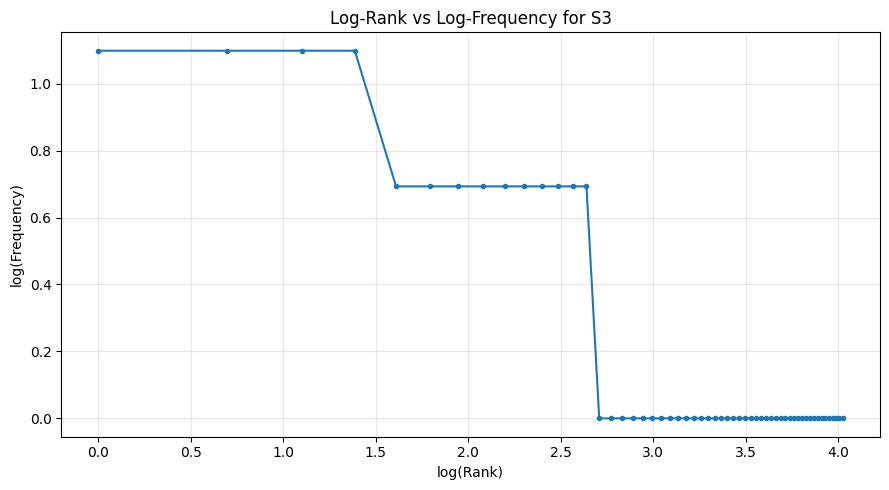

Top 5 bigrams in S1:
('.', 'i') : 5
('yesterday', '.') : 3
('.', 'the') : 3
('.', 'can') : 2
('can', 'you') : 2

Top 5 bigrams in S3:
('since', 'yesterday') : 2
('tried', 'several') : 2
('several', 'times') : 2
('ca', "n't") : 2
("n't", 'open') : 2


In [19]:
from collections import Counter
from nltk.util import bigrams
import math
import matplotlib.pyplot as plt

# S1: all tokens from the official pipeline.
S1 = [t for p in processed_tickets.values() for t in p["tokens"]]
# S2: all tokens excluding punctuation tokens.
S2 = [t for t in S1 if not is_punct(t)]
# S3: final tokens from the official pipeline.
S3 = [t for p in processed_tickets.values() for t in p["final"]]
# S4: S3 after Porter stemming.
S4 = [porter.stem(t) for t in S3]

def corpus_statistics(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    return {
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(unique / total, 4) if total else 0
    }

stats_df = pd.DataFrame({
    name: corpus_statistics(tokens)
    for name, tokens in {
        "S1": S1, "S2": S2, "S3": S3, "S4": S4
    }.items()
}).T
display(stats_df)

print("Top 10 words in S1:")
print(Counter(S1).most_common(10))
print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

ranked_words = Counter(S3).most_common()
ranks = list(range(1, len(ranked_words) + 1))
frequencies = [freq for _, freq in ranked_words]
plt.figure(figsize=(9, 5))
plt.plot([math.log(r) for r in ranks],
         [math.log(f) for f in frequencies],
         marker="o", markersize=3)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 5 bigrams in S1:")
for bigram, count in Counter(bigrams(S1)).most_common(5):
    print(bigram, ":", count)

print("\nTop 5 bigrams in S3:")
for bigram, count in Counter(bigrams(S3)).most_common(5):
    print(bigram, ":", count)

**Your answer:** TTR is unique-token count divided by total-token count. From S1 to S4, stopword/punctuation removal and Porter stemming change both the vocabulary size and total token count. Stemming can merge different forms into one stem, reducing unique-token count, so the TTR changes according to the balance between those two effects. Refer to your displayed statistics for the direction and values in your dataset.